Integrantes:
- Caio Merçon Pereira Carvalho – 231028746
- Lucas Vasconcelos Pirani Carneiro – 251031785
- Pedro Zambrozi Brunhara – 242039579

Etapas 1 e 2:

In [ ]:
import networkx as nx
import pandas as pd
import random
import urllib

SEED = 231028746 + 251031785 + 242039579 # Soma das 3 matrículas para garantir uma seed única
random.seed(SEED)

url="https://snap.stanford.edu/data/facebook_combined.txt.gz"
arquivo_local = "facebook_combined.txt.gz"
urllib.request.urlretrieve(url, arquivo_local)

G_full = nx.read_edgelist(arquivo_local, nodetype = int)
print(f"Estatísticas do Grafo Completo:")
print(f" - Total de nós: {G_full.number_of_nodes()}")
print(f" - Total de arestas: {G_full.number_of_edges()}")

nos_selecionados=random.sample(list(G_full.nodes()),404)
G_sub=G_full.subgraph(nos_selecionados).copy()

print(f"\nSubgrafo de estudo extraído:")
print(f" - Nós selecionados: {G_sub.number_of_nodes()}")
print(f" - Arestas preservadas: {G_sub.number_of_edges()}")

Estatísticas do Grafo Completo:
 - Total de nós: 4039
 - Total de arestas: 88234

Subgrafo de estudo extraído:
 - Nós selecionados: 404
 - Arestas preservadas: 810


Etapa 3:


In [ ]:
comunidades = nx.community.louvain_communities(G_sub, seed = SEED)
print(comunidades)

centralidade = nx.degree_centrality(G_sub)
print(centralidade)

cent_intermediacao = nx.betweenness_centrality(G_sub)
print(cent_intermediacao)

cent_proximidade = nx.closeness_centrality(G_sub)
print(cent_proximidade)

cent_autovetor = nx.eigenvector_centrality(G_sub)
print(cent_autovetor)

[{2304, 2177, 2498, 2057, 2379, 2511, 2512, 2451, 2389, 2582, 2199, 1913, 2522, 2143, 2336, 1955, 1959, 2280, 2151, 2223, 2161, 2547, 2101, 2617, 1982}, {2079}, {2564, 2309, 2506, 2124, 2574, 2262, 2136, 2073, 2139, 2077, 2206, 2276, 2150, 2601, 2352, 2109, 2613, 2237, 2495}, {0, 1, 259, 134, 8, 9, 17, 274, 158, 30, 291, 298, 44, 178, 54, 183, 58, 62, 319, 64, 2885, 326, 74, 203, 78, 79, 80, 339, 84, 216, 223, 106, 121}, {2448, 2114, 2628, 2166, 2361, 2156, 2317}, {349}, {2017, 2421}, {379}, {383}, {401}, {2480}, {2281, 2487}, {441, 399}, {2145, 2514, 2066, 2453, 2406}, {2528}, {2569}, {530}, {541}, {546}, {2622, 2207}, {640, 578, 670, 583}, {2337, 2346, 2061, 1998, 1999, 2639, 2009, 1951}, {621}, {649}, {657}, {667}, {668}, {619, 685}, {689}, {2740}, {2767}, {3399, 2835, 2966, 3033, 3064, 3166, 2794, 2731, 2988, 3052, 3436, 2928, 3384, 2874, 3195, 3390, 3135}, {779}, {2851}, {818}, {705, 782, 849, 856, 729, 795, 738, 804, 813, 878, 820, 694, 695, 889, 762, 766}, {852}, {3131, 2902}, {

# Etapa 04 - Gráficos

In [ ]:
# Estatística Inicias
n = G_sub.number_of_nodes()
m = G_sub.number_of_edges()
grau_medio = sum(dict(G_sub.degree()).values()) / n
densidade = nx.density(G_sub)

estatisticas = pd.DataFrame({
    "Estatística": [ "Número de Vértices", "Número de Arestas", "Grau Médio", "Densidade" ],
    "Valor": [ n, m, round(grau_medio, 2), f"{densidade * 100:.3f}%"]
})

display(estatisticas)

,Estatística,Valor
0,Número de Vértices,404
1,Número de Arestas,810
2,Grau Médio,4.01
3,Densidade,0.995%


Total de Comunidades: 105
Tamanhos das 10 Maiores Comunidades:
[47, 33, 28, 25, 24, 21, 19, 19, 17, 16]


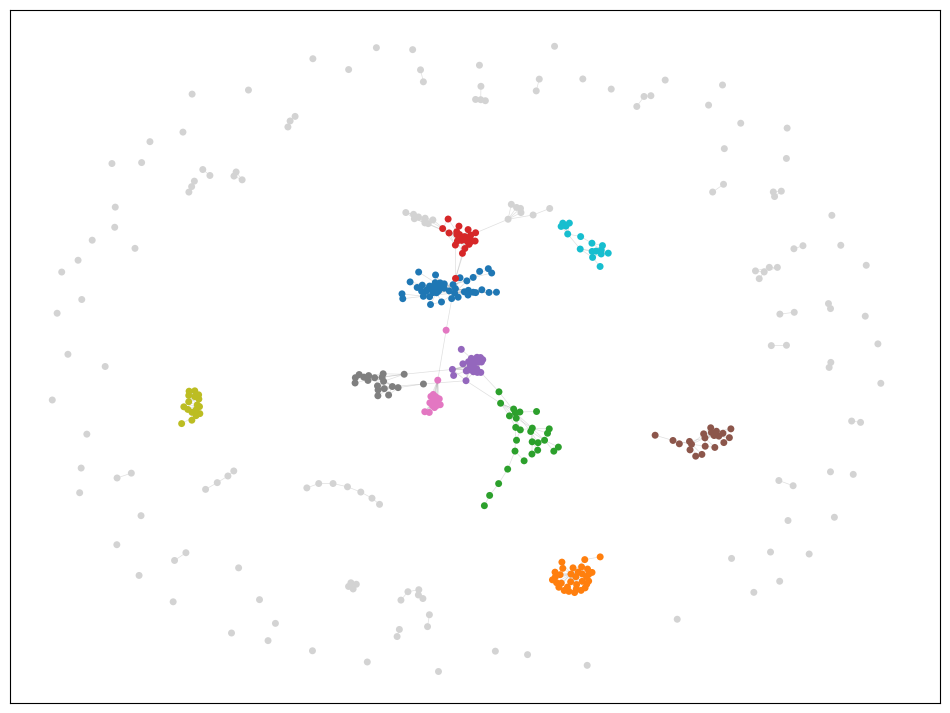

In [ ]:
# Comunidades Encontradas
import matplotlib.pyplot as plt

louvain = sorted(
    comunidades,
    key = len,
    reverse = True
)

print(f"Total de Comunidades: {len(louvain)}")
print("Tamanhos das 10 Maiores Comunidades:")
print([len(c) for c in louvain[:10]])

# Gerar as cores do Grafo
pos = nx.spring_layout(G_sub, seed = SEED)
cores_comunidades = plt.cm.tab10.colors
cor_por_no = {}

for i, comunidade in enumerate(louvain):
    cor = (
        cores_comunidades[i]
        if i < 10
        else "lightgray"
    )

    for no in comunidade:
        cor_por_no[no] = cor

cores_nos = [
    cor_por_no[no]
    for no in G_sub.nodes()
]

# Desenho do Grafo
plt.figure(figsize=(12, 9))

nx.draw_networkx_edges(
    G_sub,
    pos,
    edge_color = "gray",
    alpha = 0.25,
    width = 0.5
)

nx.draw_networkx_nodes(
    G_sub,
    pos,
    node_color = cores_nos,
    node_size = 25,
    linewidths = 0
)

plt.show()


Dez Maiores Valores - Centralidade de grau


,Nó,Valor
0,0,0.07692
1,2199,0.04715
2,3291,0.04467
3,2206,0.04218
4,1199,0.04218
5,3320,0.04218
6,2336,0.03970
7,2951,0.03970
8,2139,0.03722
9,2223,0.03722


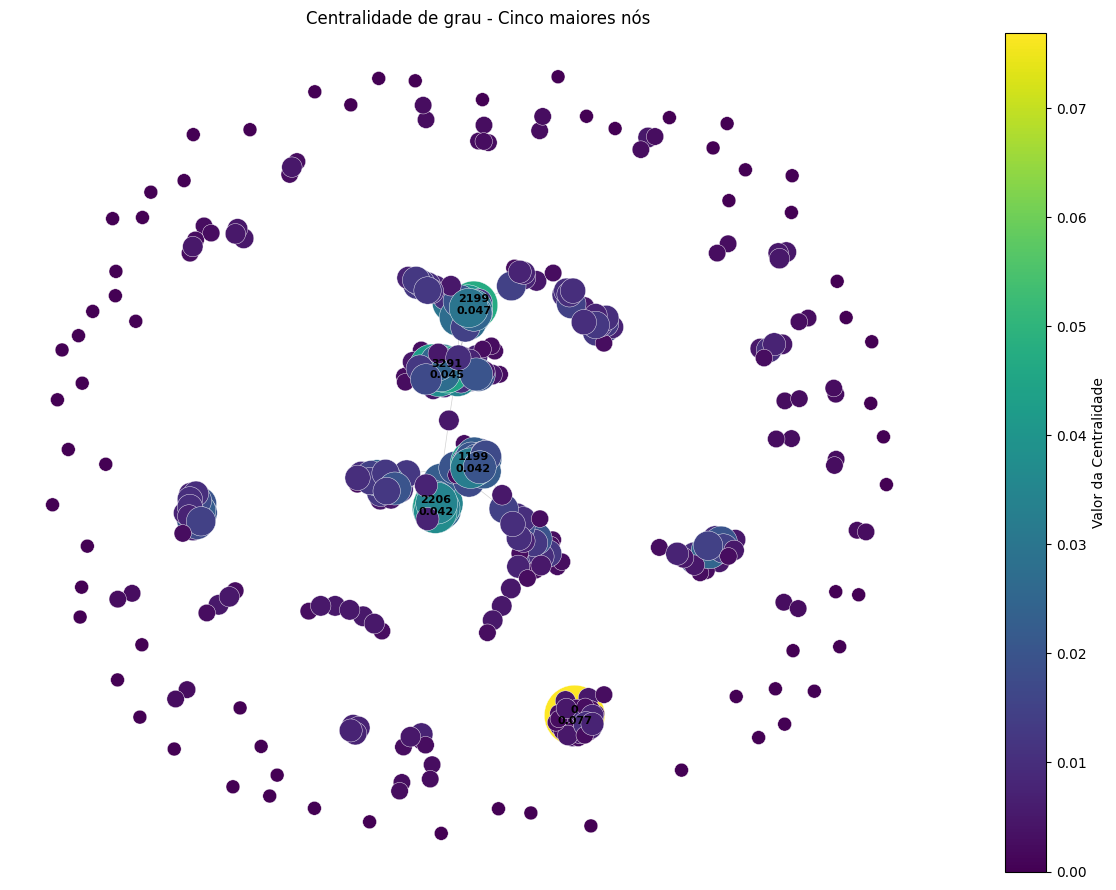


Dez Maiores Valores - Centralidade de intermediação


,Nó,Valor
0,934,0.01325
1,1155,0.01141
2,1982,0.00916
3,2262,0.00889
4,2506,0.00861
5,921,0.00671
6,366,0.00605
7,1404,0.00601
8,0,0.00583
9,2512,0.00553


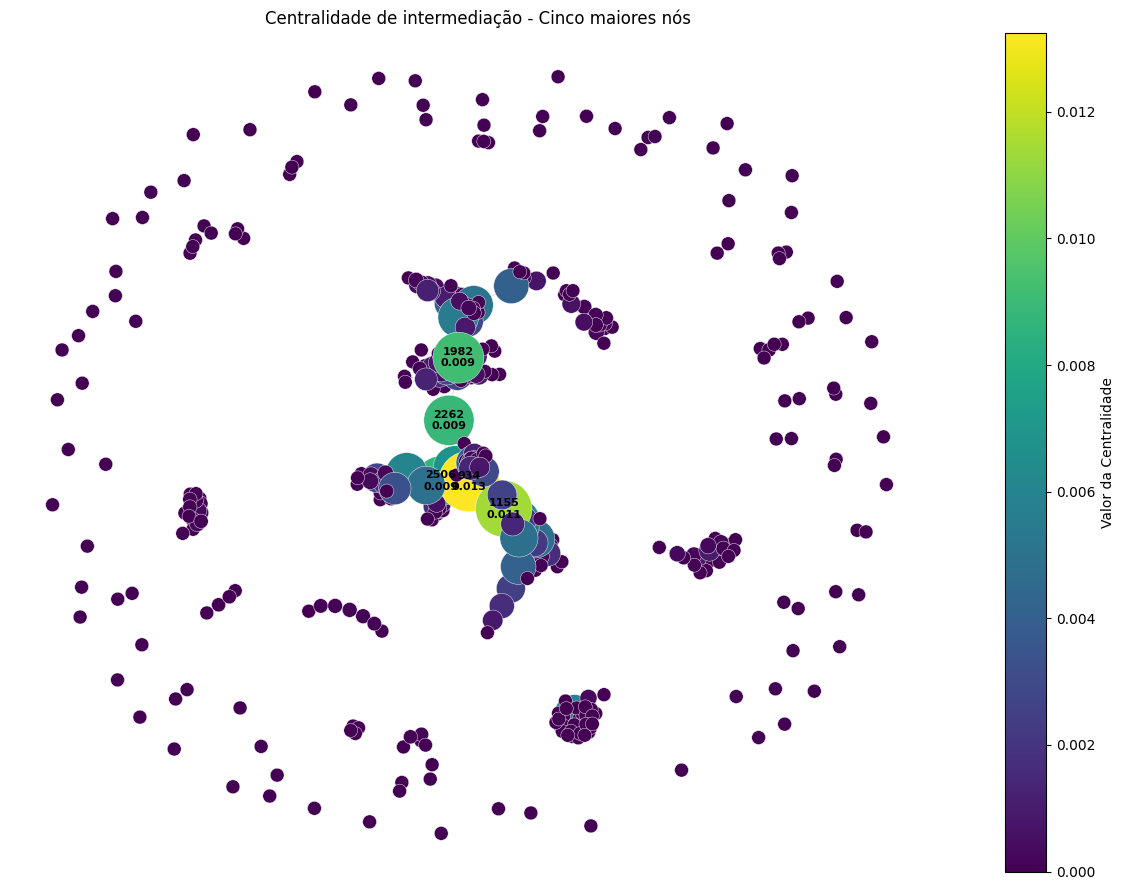


Dez Maiores Valores - Centralidade de proximidade


,Nó,Valor
0,0,0.07700
1,3291,0.06563
2,3002,0.06326
3,2951,0.06251
4,3198,0.06035
5,934,0.05790
6,3038,0.05770
7,3345,0.05707
8,3113,0.05646
9,3360,0.05586


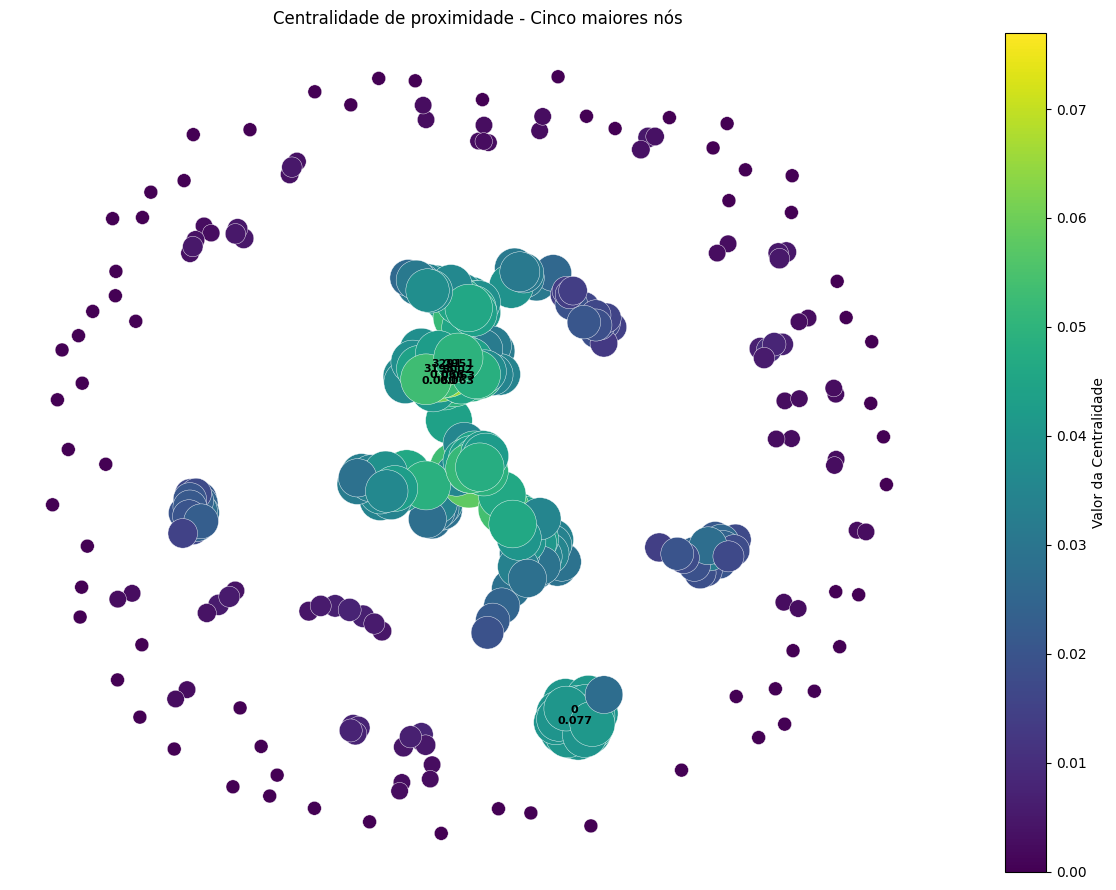


Dez Maiores Valores - Centralidade de autovetor


,Nó,Valor
0,2206,0.29483
1,2309,0.28430
2,2139,0.27741
3,2073,0.27150
4,2601,0.27150
5,2564,0.27039
6,2276,0.26874
7,2352,0.26866
8,2495,0.25497
9,2124,0.24475


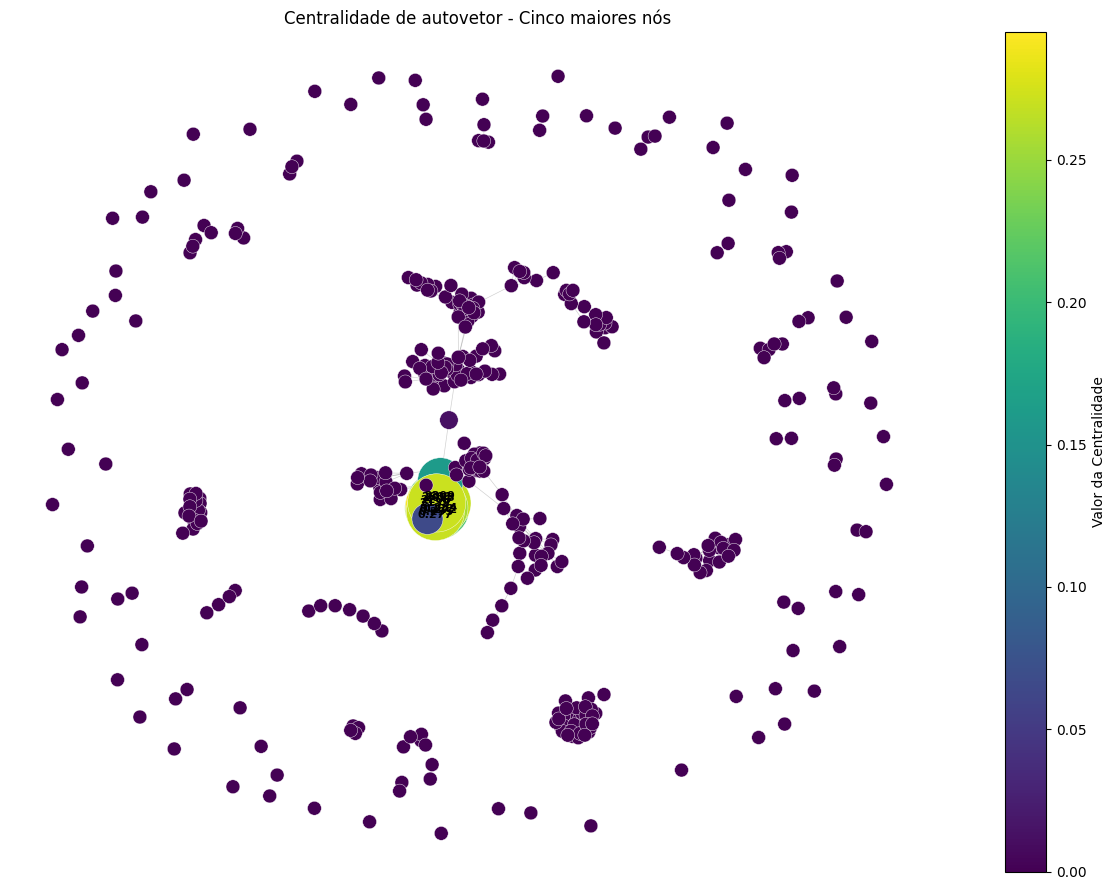

In [ ]:
medidas = {
    "Grau": centralidade,
    "Intermediação": cent_intermediacao,
    "Proximidade": cent_proximidade,
    "Autovetor": cent_autovetor,
}

pos = nx.spring_layout(G_sub, seed=SEED)

for nome, valores in medidas.items():
    top10 = sorted(valores.items(), key=lambda item: item[1], reverse=True)[:10]
    tabela = pd.DataFrame(top10, columns=["Nó", "Valor"])
    print(f"\nDez Maiores Valores - Centralidade de {nome.lower()}")
    display(tabela.style.format({"Valor": "{:.5f}"}))

    maior = max(valores.values())
    tamanhos = [100 + 1800 * valores[no] / maior for no in G_sub.nodes()]

    top5 = [no for no, _ in top10[:5]]
    rotulos = {no: f"{no}\n{valores[no]:.3f}" for no in top5}

    plt.figure(figsize=(12, 9))
    nx.draw_networkx_edges(G_sub, pos, alpha = 0.18, width = 0.5)
    nos = nx.draw_networkx_nodes(
        G_sub, pos,
        node_size = tamanhos,
        node_color = [valores[no] for no in G_sub.nodes()],
        cmap = plt.cm.viridis,
        edgecolors = "white",
        linewidths = 0.3,
    )
    nx.draw_networkx_labels(
        G_sub, pos, labels=rotulos, font_size=8, font_weight="bold"
    )
    plt.title(f"Centralidade de {nome.lower()} - Cinco maiores nós")
    plt.colorbar(nos, label="Valor da Centralidade")
    plt.axis("off")
    plt.tight_layout()

    plt.show()